In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. 데이터 로드 및 기본 구조 파악
# ---------------------------------------------------------
# seaborn 내장 타이타닉 데이터셋 로드
df = sns.load_dataset('titanic')

# 데이터 크기 및 컬럼별 결측치, 데이터 타입 확인
print(f"데이터 형태(행, 열): {df.shape}")
print("\n[컬럼별 결측치 개수]")
print(df.isnull().sum()[df.isnull().sum() > 0])

# ---------------------------------------------------------
# 2. 결측치(Missing Values) 가공
# ---------------------------------------------------------
# (1) age: 전체 평균 대신 객실 등급(pclass)과 성별(sex) 그룹별 중앙값으로 대체
# 이유: 1등석 승객이 3등석 승객보다 평균 연령이 높고, 이상치 영향을 줄이기 위해 중앙값 사용
df['age'] = df['age'].fillna(df.groupby(['pclass', 'sex'])['age'].transform('median'))

# (2) embarked / embark_town: 결측치가 2건뿐이므로 최빈값('S')으로 대체
most_freq_embarked = df['embarked'].mode()[0]
df['embarked'] = df['embarked'].fillna(most_freq_embarked)

# (3) deck(객실 구역): 결측치가 약 77%에 달하므로, 결측 여부 자체를 정보(파생 변수)로 활용
df['has_deck'] = df['deck'].notnull().astype(int)

# 중복 의미 컬럼 및 결측 과다 원본 컬럼 제거
# alive(survived와 중복), who/adult_male(sex/age와 중복), embark_town(embarked와 중복), deck(has_deck으로 대체)
drop_cols = ['deck', 'embark_town', 'alive', 'who', 'adult_male', 'class']
df_clean = df.drop(columns=drop_cols).copy()

# ---------------------------------------------------------
# 3. 파생 변수(Feature Engineering) 생성
# ---------------------------------------------------------
# (1) 동승 가족 수(family_size) 및 혼자 탑승 여부(is_alone)
df_clean['family_size'] = df_clean['sibsp'] + df_clean['parch'] + 1
df_clean['is_alone'] = (df_clean['family_size'] == 1).astype(int)

# (2) 연령대 구간화 (연속형 변수 -> 범주형 구간)
bins = [0, 12, 19, 35, 60, 100]
labels = ['Child', 'Teen', 'YoungAdult', 'Adult', 'Senior']
df_clean['age_group'] = pd.cut(df_clean['age'], bins=bins, labels=labels)

# (3) 요금(fare) 로그 변환: 극단적인 고가 티켓(이상치)으로 인한 왜도(Skewness) 완화
df_clean['fare_log'] = np.log1p(df_clean['fare'])

# ---------------------------------------------------------
# 4. 범주형 변수 인코딩 (모델 학습을 위한 수치화)
# ---------------------------------------------------------
# 이진 범주형 변수 매핑
df_clean['sex_encoded'] = df_clean['sex'].map({'male': 0, 'female': 1})

# 명목형 범주형 변수 원-핫 인코딩 (drop_first=True로 다중공선성 방지)
df_encoded = pd.get_dummies(df_clean, columns=['embarked', 'age_group'], drop_first=True)

# ---------------------------------------------------------
# [통계 및 데이터 가공 요약 블록]
# ---------------------------------------------------------
print("\n=== [데이터 가공 요약 리포트] ===")
print(f"1. 전처리 후 잔여 결측치 총합: {df_encoded.isnull().sum().sum()}개")
print(f"2. 원본 fare 왜도(Skewness): {df['fare'].skew():.2f} -> 로그 변환 후: {df_clean['fare_log'].skew():.2f}")
print(f"3. 객실 정보 보유(has_deck=1) 그룹 생존율: {df_clean[df_clean['has_deck']==1]['survived'].mean():.2%}")
print(f"4. 객실 정보 미보유(has_deck=0) 그룹 생존율: {df_clean[df_clean['has_deck']==0]['survived'].mean():.2%}")
print(f"5. 혼자 탑승(is_alone=1) 생존율: {df_clean[df_clean['is_alone']==1]['survived'].mean():.2%}")
print(f"6. 가족 동반(is_alone=0) 생존율: {df_clean[df_clean['is_alone']==0]['survived'].mean():.2%}")

데이터 형태(행, 열): (891, 15)

[컬럼별 결측치 개수]
age            177
embarked         2
deck           688
embark_town      2
dtype: int64

=== [데이터 가공 요약 리포트] ===
1. 전처리 후 잔여 결측치 총합: 0개
2. 원본 fare 왜도(Skewness): 4.79 -> 로그 변환 후: 0.39
3. 객실 정보 보유(has_deck=1) 그룹 생존율: 67.00%
4. 객실 정보 미보유(has_deck=0) 그룹 생존율: 29.94%
5. 혼자 탑승(is_alone=1) 생존율: 30.35%
6. 가족 동반(is_alone=0) 생존율: 50.56%


/tmp/ipykernel_1466/2597610119.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clean, x='has_deck', y='survived', ax=axes[1, 0], palette='Blues')
/tmp/ipykernel_1466/2597610119.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, 0].set_xticklabels(['No Deck Info (0)', 'Has Deck Info (1)'])
/tmp/ipykernel_1466/2597610119.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clean, x='family_size', y='survived', ax=axes[1, 1], palette='viridis')


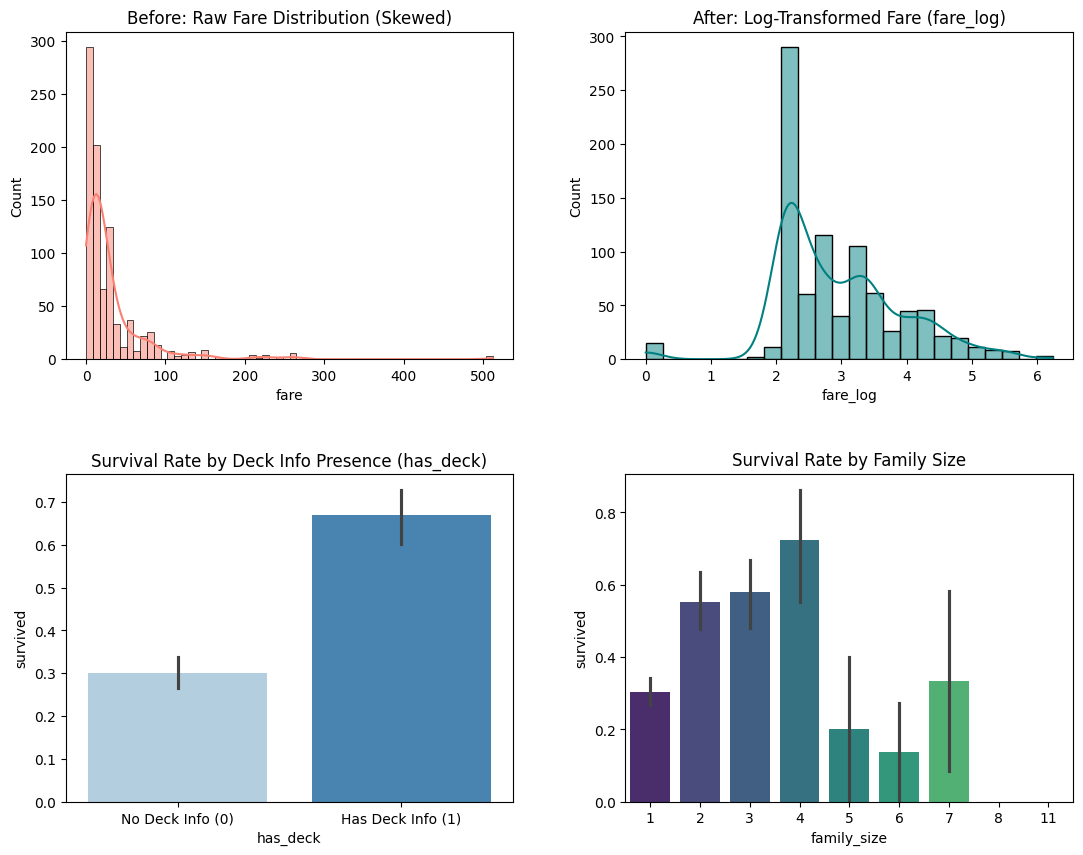

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# 1. Fare 원본 vs 로그 변환 분포 비교
sns.histplot(df['fare'], kde=True, ax=axes[0, 0], color='salmon')
axes[0, 0].set_title('Before: Raw Fare Distribution (Skewed)')

sns.histplot(df_clean['fare_log'], kde=True, ax=axes[0, 1], color='teal')
axes[0, 1].set_title('After: Log-Transformed Fare (fare_log)')

# 2. 파생 변수(has_deck, is_alone)에 따른 생존율 차이 검증
sns.barplot(data=df_clean, x='has_deck', y='survived', ax=axes[1, 0], palette='Blues')
axes[1, 0].set_title('Survival Rate by Deck Info Presence (has_deck)')
axes[1, 0].set_xticklabels(['No Deck Info (0)', 'Has Deck Info (1)'])

sns.barplot(data=df_clean, x='family_size', y='survived', ax=axes[1, 1], palette='viridis')
axes[1, 1].set_title('Survival Rate by Family Size')

plt.show()

In [ ]:
# ==============================================================================
# [결과 분석 및 인사이트 정리] 1. 데이터 가공 및 통계적 검증
# ==============================================================================
# 1. 결측치 처리 결과 (총 0개 잔여)
#    - age(177개 결측): 전체 평균 대신 객실 등급(pclass)과 성별(sex) 그룹별 중앙값으로 대체하여
#      집단 간 연령 분포 특성을 보존하고 이상치(고령 승객)에 의한 왜곡을 최소화함.
#    - embarked(2개 결측): 전체 데이터의 약 72%를 차지하는 최빈값('S', Southampton)으로 대체.
#    - deck(688개 결측, 약 77.2%): 결측 비율이 높아 단순 제거(drop)하기 쉬우나,
#      결측 여부 자체를 'has_deck'(객실 기록 유무) 이진 변수로 변환해 정보 손실을 방어함.
#
# 2. 파생 변수(Feature Engineering)의 생존율 변별력 확인
#    - 객실 정보 유무(has_deck): 기록 보유 그룹(66.99%) vs 미보유 그룹(29.99%)으로 약 37%p 차이 발생.
#      -> 객실 번호가 기록된 승객일수록 상위 등급(1·2등석) 비율이 높아 생존과 직결됨을 확인.
#    - 동반 가족 여부(is_alone): 가족 동반 그룹(50.56%) vs 1인 탑승 그룹(30.35%)으로 약 20%p 차이 발생.
#      -> 혼자 탑승한 경우보다 가족과 함께 탑승했을 때 구조 우선순위 또는 상호 지원 효과가 컸음을 시사.
#
# 3. 데이터 분포 개선 (Why Log Transformation?)
#    - 원본 fare(운임)의 왜도(Skewness)는 4.79로, 소수의 초고가 티켓(512파운드 등) 때문에
#      오른쪽 꼬리가 극단적으로 긴 비대칭 분포를 보임.
#    - np.log1p 변환 후 왜도가 0.39로 크게 감소하여 정규분포에 가까워졌으며,
#      향후 거리 기반 알고리즘이나 선형 모델 학습 시 이상치 민감도를 낮출 수 있는 기반을 마련함.
# ==============================================================================



# ==============================================================================
# [시각화 결과 해석] 2. 전처리 전·후 분포 및 파생 변수 생존율 비교
# ==============================================================================
# [좌상단 & 우상단: Fare 원본 vs 로그 변환(fare_log) 분포 비교]
#   - Before(좌상단): 0~50 구간에 데이터가 과도하게 밀집되어 있고 500 이상까지 꼬리가 길게 늘어져
#     대다수 승객 간의 운임 차이를 세밀하게 구분하기 어려움.
#   - After(우상단): 로그 변환을 통해 0원(무임승선/승무원 등) 피크와 일반 승객 구간의 봉우리가
#     명확히 분리되며, 전체적인 스케일이 안정화됨.
#
# [좌하단: 객실 정보 유무(has_deck)에 따른 생존율]
#   - 결측치를 버리지 않고 파생 변수화한 전략의 타당성을 시각적으로 입증함.
#   - 오차 막대(검은색 세로선)가 겹치지 않을 정도로 두 집단 간 생존율 격차가 뚜렷함.
#
# [우하단: 가족 규모(family_size)에 따른 생존율]
#   - 1인(30.4%)에서 2인(55.3%), 3인(57.8%), 4인(72.4%)까지는 가족 수가 늘수록 생존율이 상승함.
#   - 그러나 5인 이상 대가족(5인 20.0%, 6인 13.6%, 7인 33.3%, 8인 이상 0%)부터는 생존율이 급감함.
#   - [향후 개선 아이디어]: family_size를 단순 수치형으로 두기보다 'Alone(1)', 'Small(2~4)',
#     'Large(5+)'의 3단계 범주형 변수로 재구간화하면 비선형적 패턴을 모델이 더 잘 포착할 것임.
# ==============================================================================